# Tabula Sapiens: IMSTE and UMAP embeddings

Fit UMAP and IMSTE once on a balanced Tabula Sapiens sample, then show the same three layouts with two independent colorings: tissue and cell type. The sample cap is applied to one selected annotation (`SAMPLE_BY`) and the resulting cells are shared by both rows.

The expression workflow starts from the raw-count layer, normalizes each cell to 10,000 counts, applies `log1p`, selects highly variable genes, scales them, and computes PCA. Labels are used only for sampling and coloring, never as embedding features.

In [1]:
%load_ext autoreload
%autoreload 2

%config InlineBackend.figure_format = 'retina'

from pathlib import Path
import sys
import time
import shutil
import zipfile
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from IPython.display import display

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").is_file()
     and (path / "imste" / "__init__.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Could not locate the IMSTE repository from the notebook working directory.")
for local_path in (PROJECT_ROOT, PROJECT_ROOT / "notebooks" / "src"):
    local_path = str(local_path)
    if local_path in sys.path:
        sys.path.remove(local_path)
    sys.path.insert(0, local_path)
import imste
if not Path(imste.__file__).resolve().is_relative_to(PROJECT_ROOT.resolve()):
    raise RuntimeError("This kernel loaded IMSTE from another location; restart and run from the top.")
from imste import IteratedMinimumSpanningTreeEmbedder

DATA_DIR = PROJECT_ROOT / "data" / "tabula_sapiens"
ARCHIVE_PATH = DATA_DIR / "TabulaSapiens_v1.h5ad.zip"
H5AD_PATH = DATA_DIR / "TabulaSapiens.h5ad"
if not H5AD_PATH.is_file():
    if not ARCHIVE_PATH.is_file():
        raise FileNotFoundError(f"Expected the dataset archive at {ARCHIVE_PATH}.")
    try:
        with zipfile.ZipFile(ARCHIVE_PATH) as archive:
            h5ad_members = [name for name in archive.namelist() if name.lower().endswith(".h5ad")]
            if len(h5ad_members) != 1:
                raise RuntimeError(f"Expected one H5AD file in {ARCHIVE_PATH.name}; found {h5ad_members}.")
            member = archive.getinfo(h5ad_members[0])
            required_bytes = member.file_size + 1_000_000_000
            if shutil.disk_usage(DATA_DIR).free < required_bytes:
                raise OSError(
                    f"Not enough free space to extract {member.file_size / 1e9:.1f} GB; "
                    f"need at least {required_bytes / 1e9:.1f} GB free."
                )
            print(f"Extracting {member.filename} ({member.file_size / 1e9:.1f} GB)...")
            with archive.open(member) as source, H5AD_PATH.open("wb") as destination:
                shutil.copyfileobj(source, destination, length=16 * 1024 * 1024)
    except zipfile.BadZipFile as error:
        raise RuntimeError(
            "The Tabula Sapiens ZIP is incomplete or invalid. Wait for the download to finish, then rerun this cell."
        ) from error
    print(f"Extracted dataset to {H5AD_PATH}; the source ZIP is retained.")

RANDOM_STATE = 42
MAX_CELLS_PER_CLASS = 5000  # Set to None to use every cell.
MIN_CELLS_PER_CELL_TYPE = 5000  # Exclude cell types with fewer source cells; set to None to disable.
SAMPLE_BY = "cell_type"  # "cell_type" or "tissue"; both rows use this same sample.
TARGET_SUM = 10_000
N_HVG = 4_000
N_PCS = 300
METRIC = 'euclidean'

## Load annotations and cap cells per class

The source object is opened in backed mode so the full expression matrix is not loaded just to inspect labels. Cell types below `MIN_CELLS_PER_CELL_TYPE` source cells are filtered out first. Then we sample up to `MAX_CELLS_PER_CLASS` cells within each class of `SAMPLE_BY`; setting either threshold to `None` disables that filter. A fixed random seed makes the selected cells reproducible.

Source: 483,152 cells × 58,870 genes
Cell-type filter: kept 30/177 types with at least 5000 cells; selected 150,000 of 483,152 source cells.
Sample cap: 5000 cells per cell_type class.
Tissue annotation: organ_tissue; cell-type annotation: cell_ontology_class


,organ_tissue,cell_ontology_class,cells
0,Bladder,b cell,60
1,Bladder,fibroblast,873
2,Bladder,macrophage,773
3,Bladder,nk cell,271
4,Bladder,plasma cell,491
5,Bladder,t cell,987
6,Blood,"cd4-positive, alpha-beta t cell",1016
7,Blood,"cd8-positive, alpha-beta t cell",498
8,Blood,classical monocyte,2708
9,Blood,erythrocyte,4753


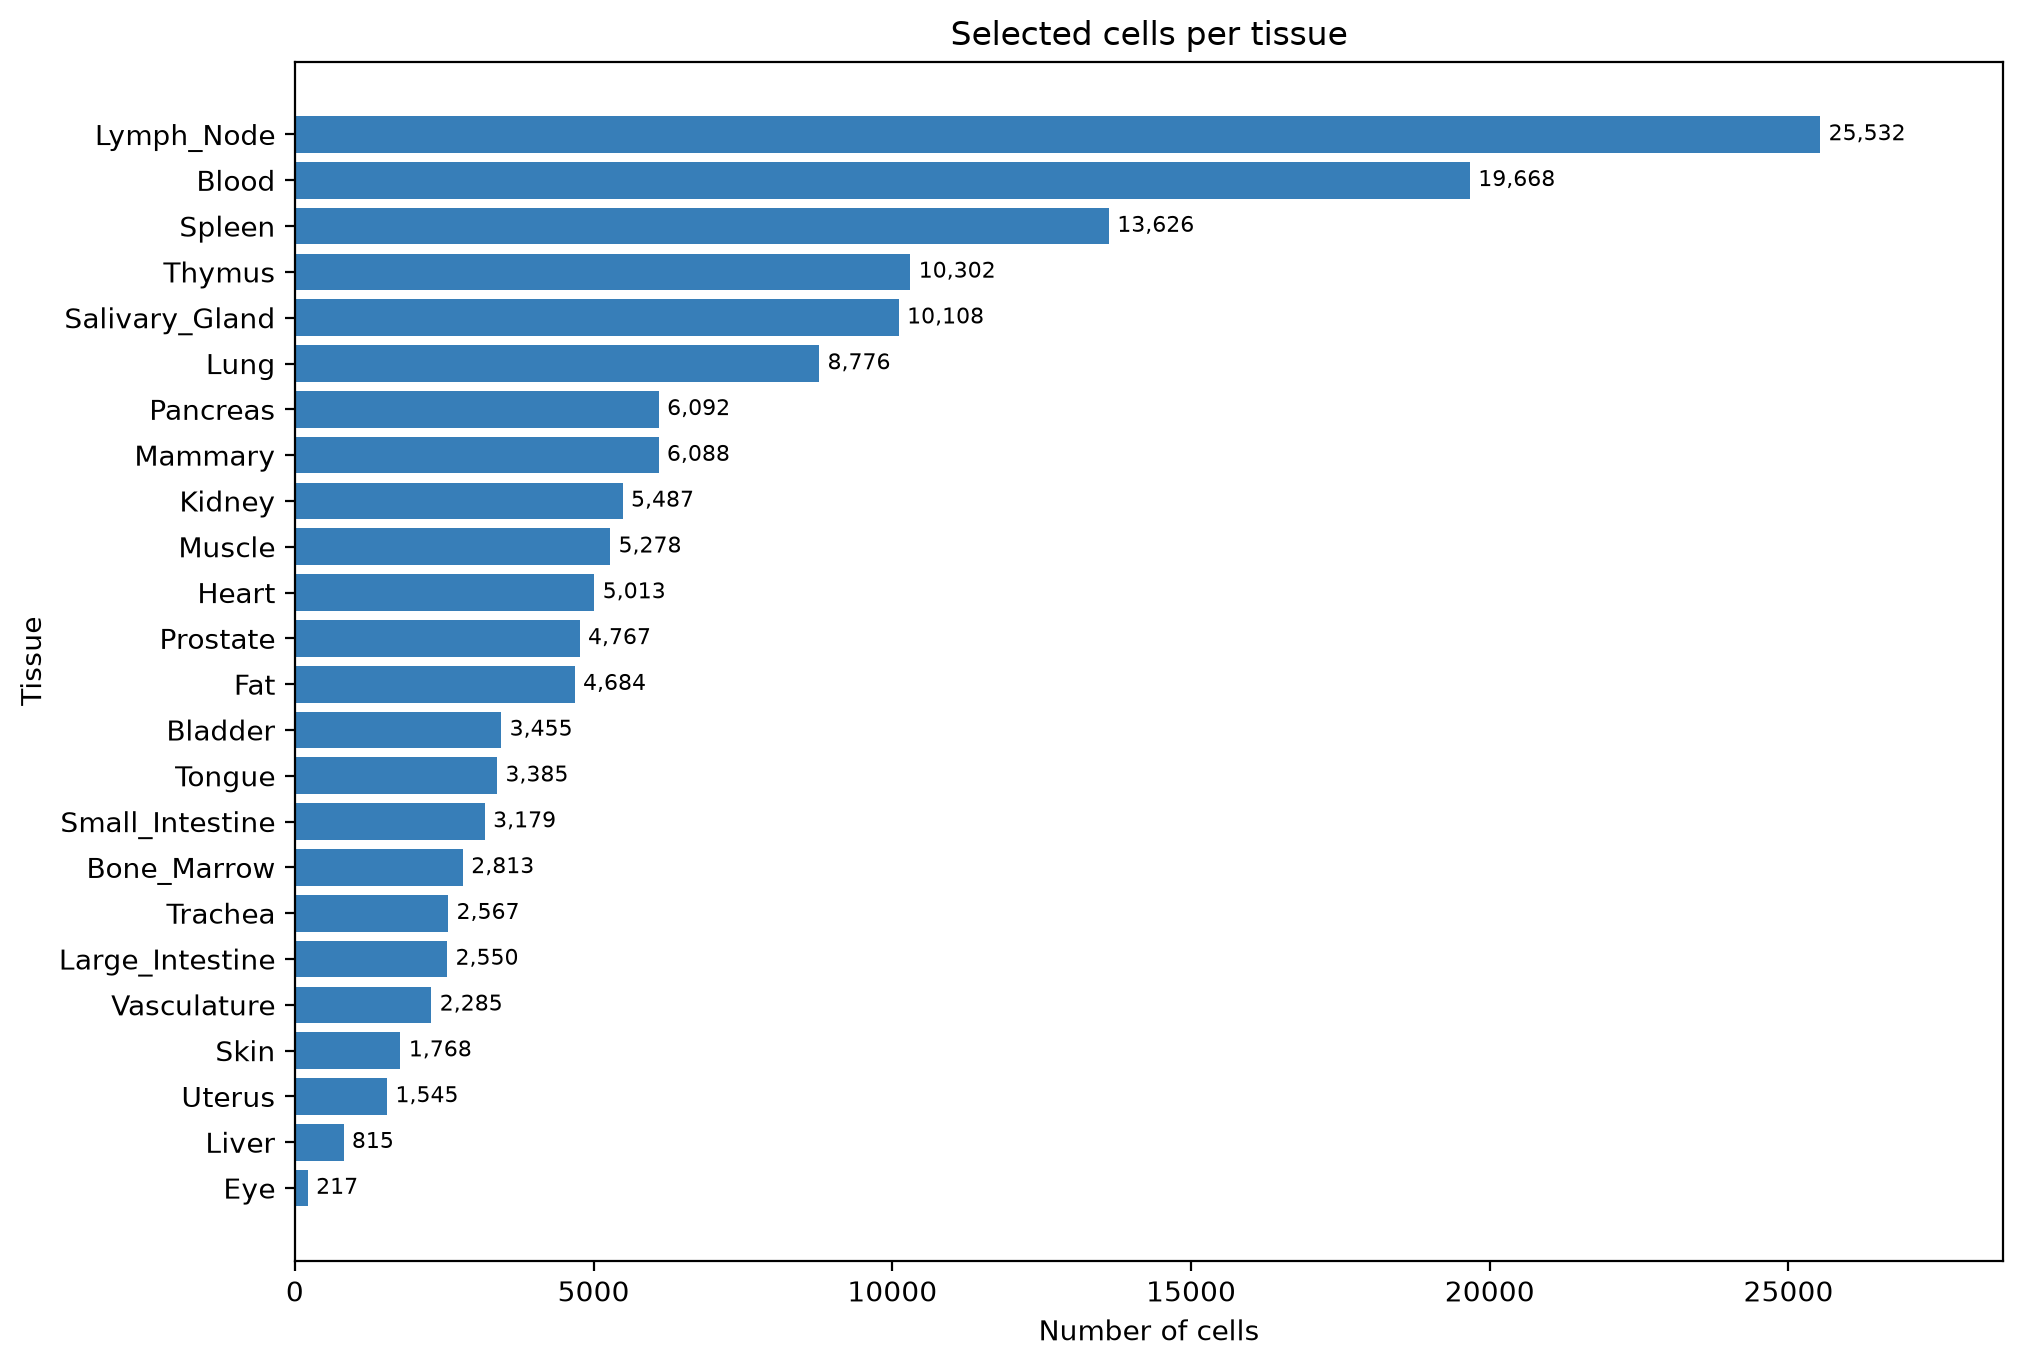

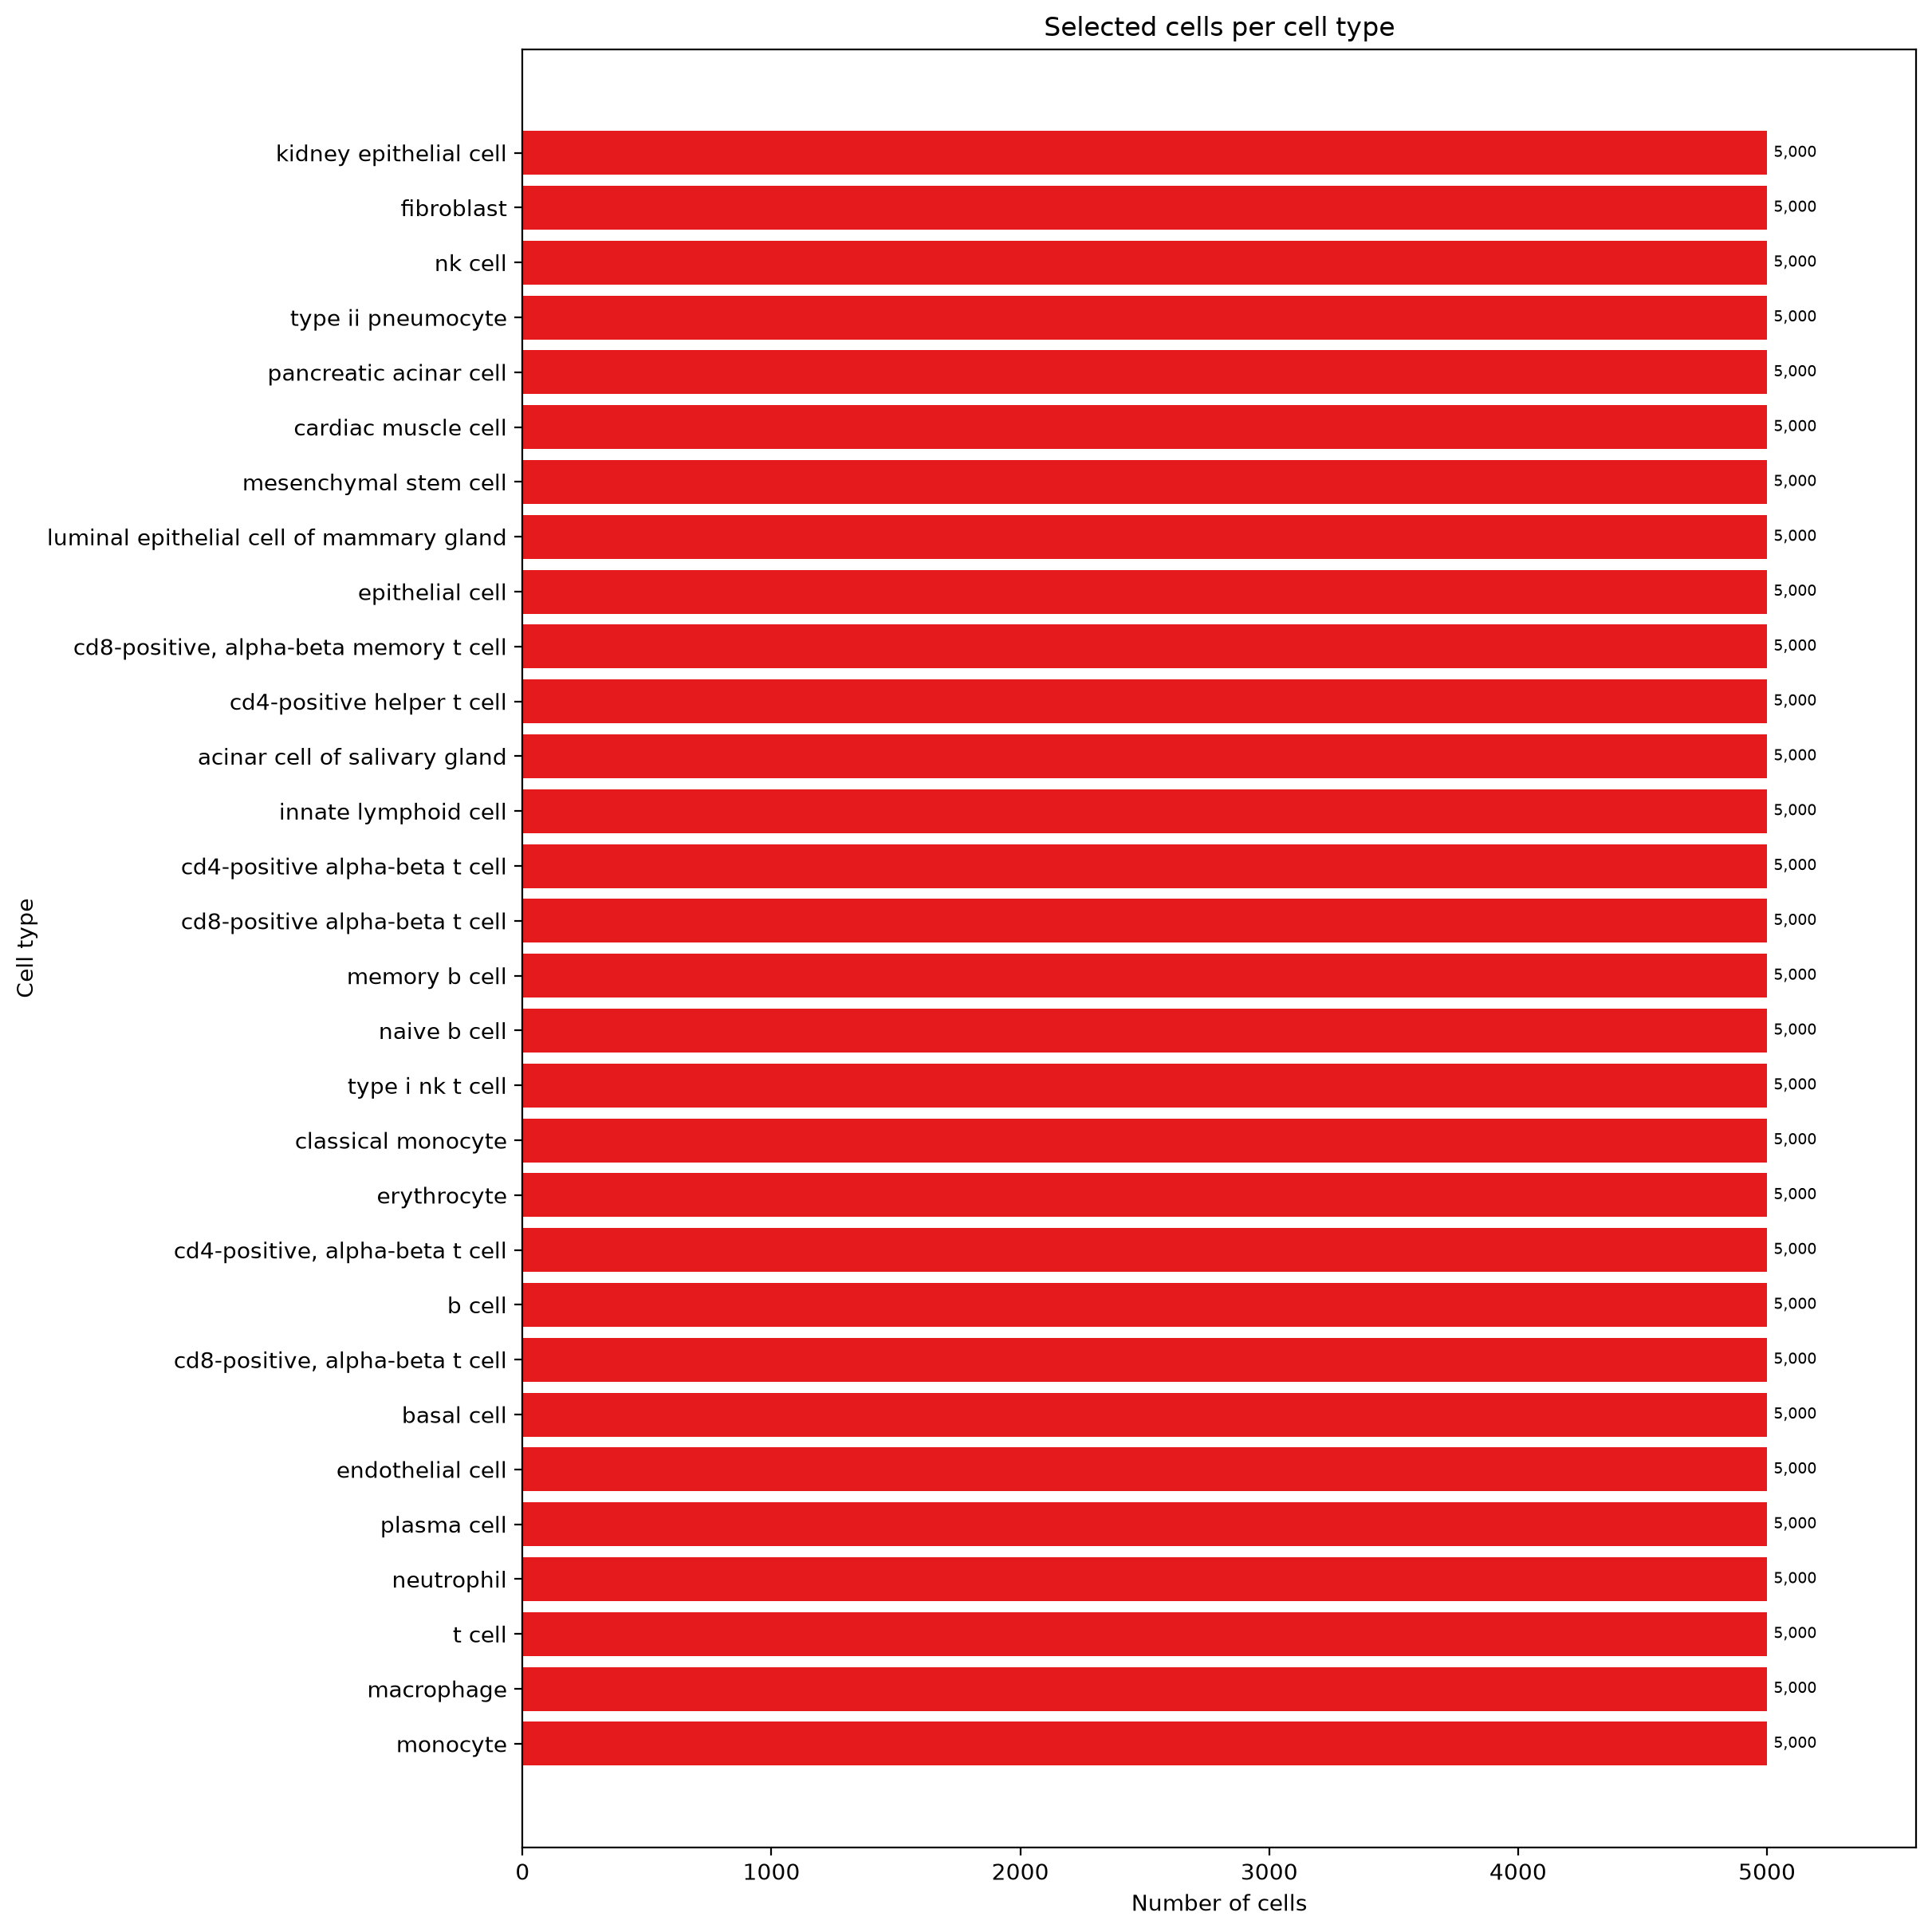

In [2]:
adata_source = sc.read_h5ad(H5AD_PATH, backed="r")

# Tabula Sapiens v1 annotation names; prefer the atlas' ontology cell types.
def first_available(columns, candidates, description):
    for name in candidates:
        if name in columns:
            return name
    raise KeyError(f"Could not find {description}; available obs columns: {list(columns)}")

tissue_column = first_available(
    adata_source.obs.columns, ("organ_tissue", "tissue", "tissue_general"), "tissue annotation"
)
cell_type_column = first_available(
    adata_source.obs.columns, ("cell_ontology_class", "cell_type", "free_annotation"), "cell-type annotation"
)
if SAMPLE_BY not in {"cell_type", "tissue"}:
    raise ValueError("SAMPLE_BY must be 'cell_type' or 'tissue'.")
sampling_column = cell_type_column if SAMPLE_BY == "cell_type" else tissue_column

obs = adata_source.obs[[tissue_column, cell_type_column]].copy()
obs = obs.astype("string").fillna("unannotated").astype(str)
cell_type_source_counts = obs[cell_type_column].value_counts()
if MIN_CELLS_PER_CELL_TYPE is not None:
    if not isinstance(MIN_CELLS_PER_CELL_TYPE, int) or MIN_CELLS_PER_CELL_TYPE < 1:
        raise ValueError("MIN_CELLS_PER_CELL_TYPE must be a positive integer or None.")
    retained_types = cell_type_source_counts[
        cell_type_source_counts >= MIN_CELLS_PER_CELL_TYPE
    ].index
else:
    retained_types = cell_type_source_counts.index

eligible_mask = obs[cell_type_column].isin(retained_types).to_numpy()
eligible_indices = np.flatnonzero(eligible_mask)
if not len(eligible_indices):
    raise ValueError("The minimum cell-type threshold removed all cells.")

if MAX_CELLS_PER_CLASS is not None:
    if not isinstance(MAX_CELLS_PER_CLASS, int) or MAX_CELLS_PER_CLASS < 1:
        raise ValueError("MAX_CELLS_PER_CLASS must be a positive integer or None.")
    rng = np.random.default_rng(RANDOM_STATE)
    selected_groups = []
    eligible_group_values = obs.iloc[eligible_indices][sampling_column].to_numpy()
    for class_name in pd.unique(eligible_group_values):
        group_members = eligible_indices[eligible_group_values == class_name]
        selected_groups.append(
            rng.choice(group_members, min(len(group_members), MAX_CELLS_PER_CLASS), replace=False)
        )
    selected_indices = np.sort(np.concatenate(selected_groups))
else:
    selected_indices = eligible_indices

print(f"Source: {adata_source.n_obs:,} cells × {adata_source.n_vars:,} genes")
print(
    f"Cell-type filter: kept {len(retained_types):,}/{len(cell_type_source_counts):,} types "
    f"with at least {MIN_CELLS_PER_CELL_TYPE if MIN_CELLS_PER_CELL_TYPE is not None else 'any'} cells; "
    f"selected {len(selected_indices):,} of {adata_source.n_obs:,} source cells."
)
print(f"Sample cap: {MAX_CELLS_PER_CLASS} cells per {SAMPLE_BY} class.")
print(f"Tissue annotation: {tissue_column}; cell-type annotation: {cell_type_column}")
display(obs.iloc[selected_indices].groupby([tissue_column, cell_type_column], observed=True).size()
        .rename("cells").reset_index().head(20))

selected_obs = obs.iloc[selected_indices]
tissue_counts = selected_obs[tissue_column].value_counts().sort_values()
cell_type_counts = selected_obs[cell_type_column].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(10, max(5, 0.28 * len(tissue_counts))), constrained_layout=True)
bars = ax.barh(tissue_counts.index, tissue_counts.values, color="#377eb8")
ax.bar_label(bars, fmt="{:,.0f}", padding=3, fontsize=8)
ax.set_xlim(0, tissue_counts.max() * 1.12)
ax.set_title("Selected cells per tissue")
ax.set_xlabel("Number of cells")
ax.set_ylabel("Tissue")
plt.show()

fig, ax = plt.subplots(figsize=(12, max(12, 0.17 * len(cell_type_counts))), constrained_layout=True)
bars = ax.barh(cell_type_counts.index, cell_type_counts.values, color="#e41a1c")
ax.bar_label(bars, fmt="{:,.0f}", padding=3, fontsize=7)
ax.set_xlim(0, cell_type_counts.max() * 1.12)
ax.set_title("Selected cells per cell type")
ax.set_xlabel("Number of cells")
ax.set_ylabel("Cell type")
plt.show()

## Normalize counts and compute the shared feature matrix

Use the raw count layer, normalize each cell to `TARGET_SUM`, and apply `log1p`. Then select highly variable genes, scale, and reduce to `N_PCS` principal components. These PCs are the shared high-dimensional input for both UMAP and IMSTE.

In [3]:
# Tabula Sapiens v1 stores unnormalized counts in layers['raw_counts'].
if "raw_counts" not in adata_source.layers:
    raise KeyError(f"Expected layers['raw_counts']; available layers: {list(adata_source.layers.keys())}")

adata_sample = adata_source[selected_indices].to_memory()
adata_source.file.close()
adata = sc.AnnData(
    X=adata_sample.layers["raw_counts"].copy(),
    obs=obs.iloc[selected_indices].copy(),
    var=adata_sample.var.copy(),
)
del adata_sample

# Standard single-cell normalization: equalize total counts per cell, then log transform.
sc.pp.normalize_total(adata, target_sum=TARGET_SUM)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=N_HVG, flavor="seurat")
adata = adata[:, adata.var["highly_variable"]].copy()
sc.pp.scale(adata, zero_center=False, max_value=10)
if not np.isfinite(adata.X.data).all():
    raise ValueError("Scaled expression matrix contains non-finite values before PCA.")
sc.tl.pca(
    adata,
    n_comps=min(N_PCS, adata.n_obs - 1, adata.n_vars - 1),
    zero_center=False,  # Sparse truncated SVD avoids implicit centering and densification.
    random_state=RANDOM_STATE,
)
X = np.asarray(adata.obsm["X_pca"], dtype=np.float32)
if not np.isfinite(X).all():
    raise ValueError("PCA produced non-finite coordinates; inspect counts and scaling.")
tissue_labels = adata.obs[tissue_column].astype(str).to_numpy()
cell_type_labels = adata.obs[cell_type_column].astype(str).to_numpy()
print(f"Feature matrix: {X.shape[0]:,} cells × {X.shape[1]} PCs from {adata.n_vars:,} HVGs")
display(pd.DataFrame({"cells": [len(X)], "tissues": [pd.Series(tissue_labels).nunique()],
                     "cell types": [pd.Series(cell_type_labels).nunique()]}))

/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:619: RuntimeWarning: divide by zero encountered in matmul
  U = Q @ Uhat
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:619: RuntimeWarning: overflow encountered in matmul
  U = Q @ Uhat
/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/utils/extmath.py:619: RuntimeWarning: invalid value encountered in matmul
  U = Q @ Uhat


Feature matrix: 150,000 cells × 300 PCs from 4,000 HVGs


,cells,tissues,cell types
0,150000,24,30


## Fit the layouts once

UMAP and IMSTE are each fitted once. The plots below reuse these coordinate arrays for both annotation rows.

## UMAP

Run the next cell by itself to refit and inspect UMAP only. It uses the already prepared `X` and updates `Z_umap`; it does not call the IMSTE estimator. The larger neighborhood and lighter repulsion are intended to reduce the long, sparse arms in the current UMAP view.


UMAP(compatibility_layout=False, init='random', min_dist=0.05, n_epochs=200, n_neighbors=100, nearest_neighbor_backend='rinnd', negative_sample_rate=3, random_state=42, repulsion_strength=0.5, verbose=True)
Mon Nov 16 13:01:08 2026 Construct fuzzy simplicial set
Mon Nov 16 13:01:08 2026 Finding Nearest Neighbors
Mon Nov 16 13:01:08 2026 Using RINND to find nearest neighbors
Building RP forest with 8 trees...
Initializing graph from 14779 leaves...
Running NN-descent for up to 17 iterations...
Iteration 1: 14810294 updates
Iteration 2: 6443625 updates
Iteration 3: 1231720 updates
Iteration 4: 328456 updates
Iteration 5: 99120 updates
Iteration 6: 37064 updates
Iteration 7: 13389 updates
Converged after 7 iterations

=== Timing Breakdown ===
Forest building:     337.041ms
Leaf initialization: 630.337ms
Candidate building:  363.746ms (7 iters)
Update iterations:  12617.184ms (7 iters)
Total measured:     13948.308ms
Mon Nov 16 13:01:23 2026 Finished Nearest Neighbor Search
Mon Nov 16 13:0

Epochs completed:   0%|            0/200 [00:00]

Mon Nov 16 13:01:31 2026 Finished embedding
UMAP fit: 22.5 s; graph components: 1; largest sizes: [np.int64(150000)]


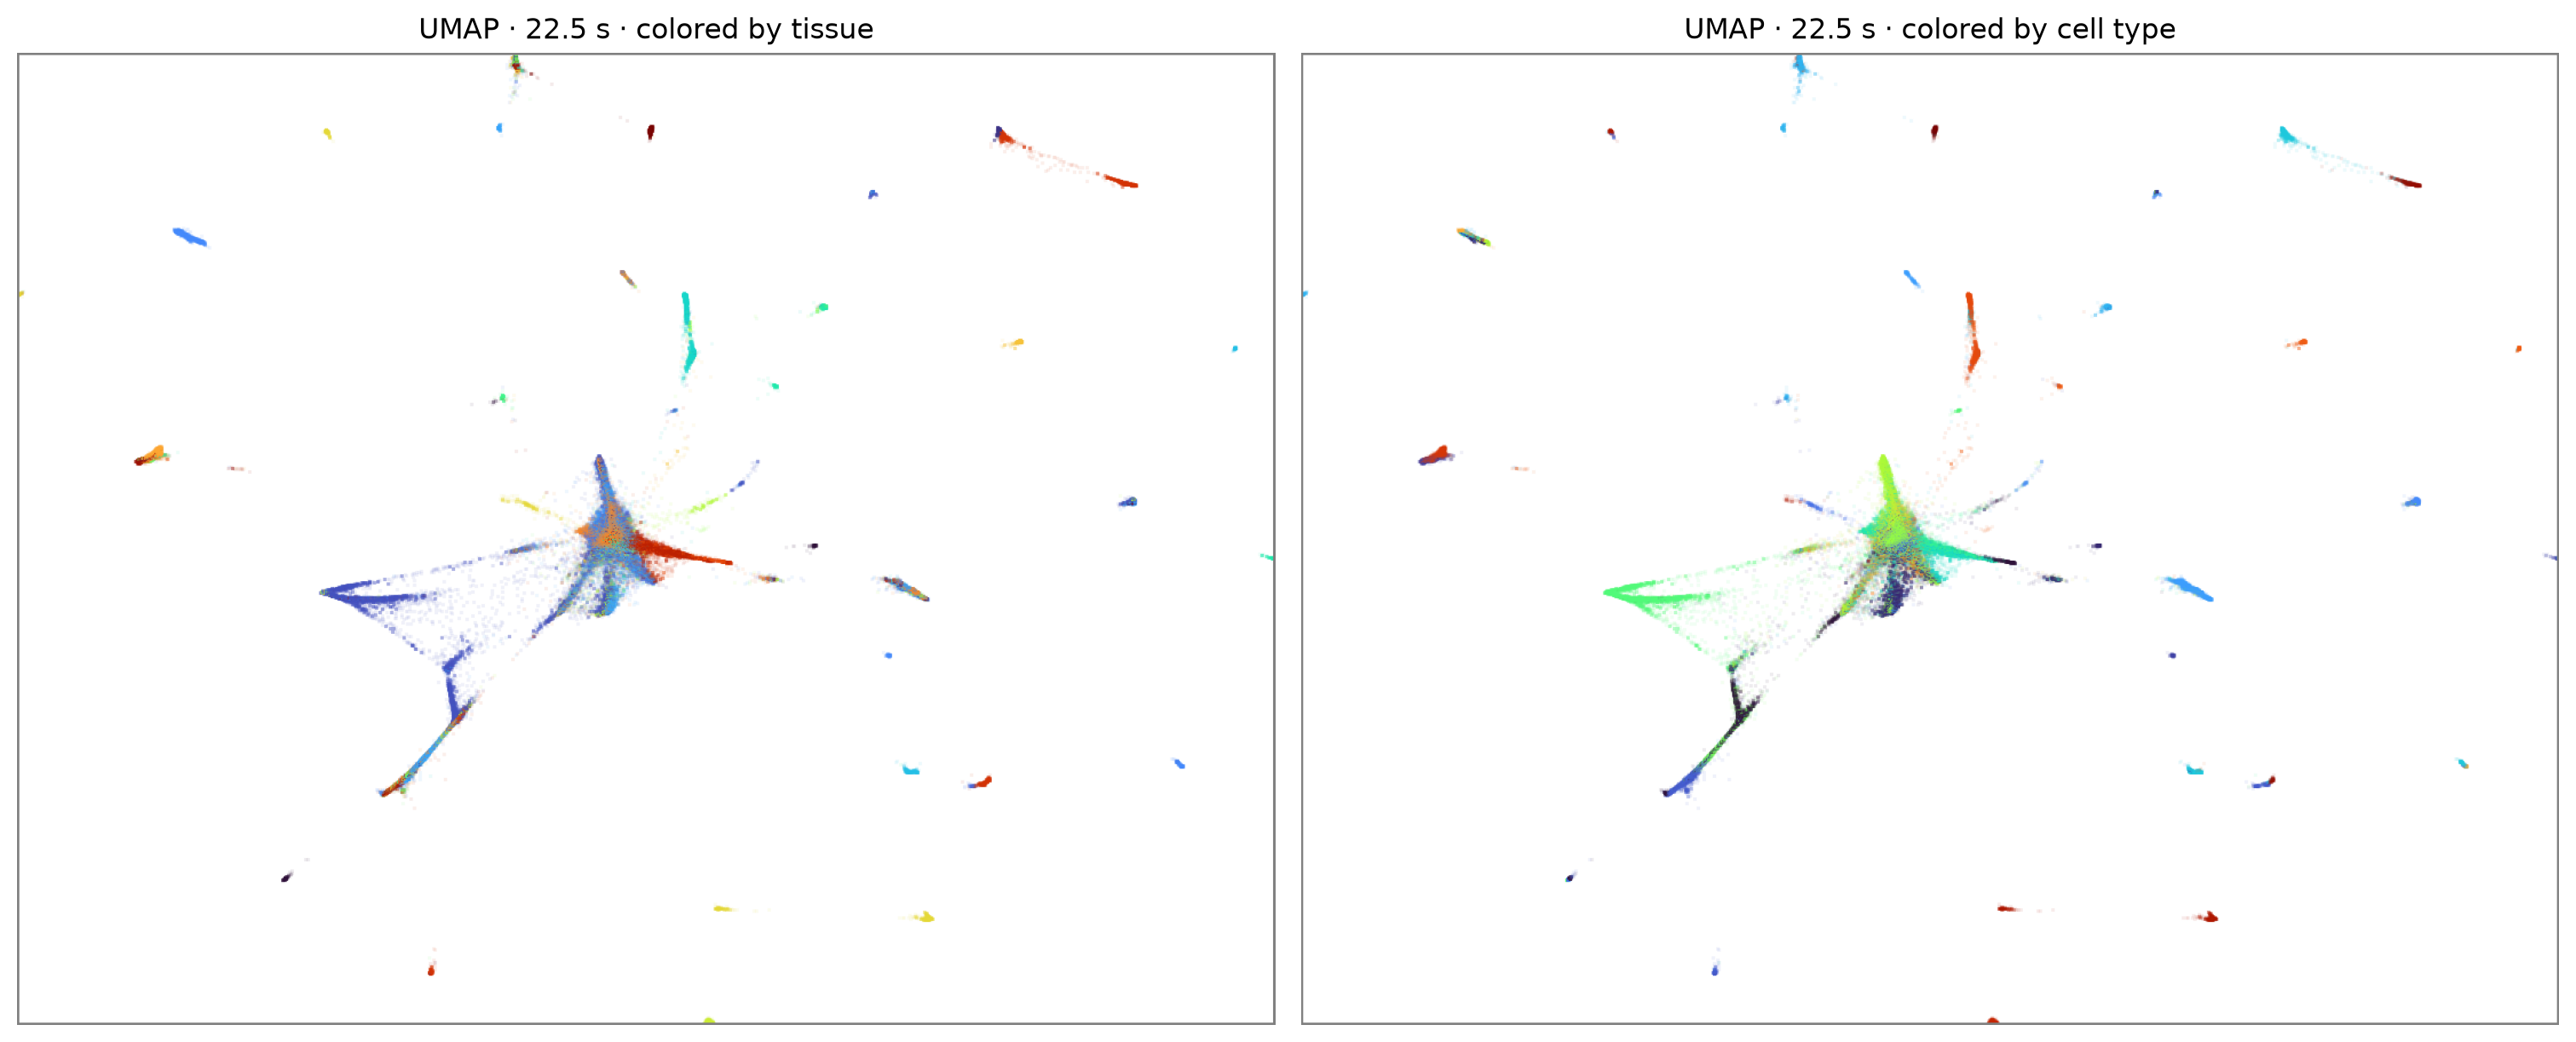

In [4]:
# UMAP-only fit: safe to rerun without running IMSTE.
import umap
from scipy.sparse.csgraph import connected_components
from imste.visualization import render_datashader_embedding

UMAP_SETTINGS = {
    "n_components": 2,
    "n_neighbors": 100,
    "min_dist": 0.05,
    "spread": 1.0,
    "repulsion_strength": 0.5,
    "negative_sample_rate": 3,
    "metric": METRIC,
    "init": "random",
    "compatibility_layout": False,
    "nearest_neighbor_backend": "rinnd",
    "random_state": RANDOM_STATE,
    "n_epochs": 200,
    "verbose": True,
}

umap_started = time.perf_counter()
umap_model = umap.UMAP(**UMAP_SETTINGS)
Z_umap = umap_model.fit_transform(X)
umap_seconds = time.perf_counter() - umap_started
component_count, component_ids = connected_components(umap_model.graph_, directed=False)
component_sizes = np.bincount(component_ids)
print(
    f"UMAP fit: {umap_seconds:.1f} s; graph components: {component_count}; "
    f"largest sizes: {sorted(component_sizes, reverse=True)[:8]}"
)

def umap_color_key(values):
    categories = list(pd.unique(values))
    cmap = plt.get_cmap("turbo", max(len(categories), 2))
    return {name: to_hex(cmap(i)) for i, name in enumerate(categories)}

fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
for ax, (label_name, label_values) in zip(
    axes, (("tissue", tissue_labels), ("cell type", cell_type_labels))
):
    image = render_datashader_embedding(
        Z_umap, label_values,
        width=1100, height=850,
        color_key=umap_color_key(label_values),
        min_alpha=20,
        background="white",
        spread_px=1,
    )
    ax.imshow(image.to_pil())
    ax.set_title(f"UMAP · {umap_seconds:.1f} s · colored by {label_name}")
    ax.set_axis_off()
plt.show()


In [ ]:
IMSTE_N_MSTS = 3
IMSTE_N_EPOCHS = 200
IMSTE_GRAVITY_STRENGTH = 0.2
IMSTE_MEAN_SHIFT_ITERATIONS = 1
IMSTE_SETTINGS = {
    "n_msts": IMSTE_N_MSTS,
    "n_epochs": IMSTE_N_EPOCHS,
    "metric": METRIC,
    "random_state": RANDOM_STATE,
    "gravity_strength": IMSTE_GRAVITY_STRENGTH,
    "mean_shift_iterations": IMSTE_MEAN_SHIFT_ITERATIONS,
}

t0 = time.perf_counter()
imste_estimator = IteratedMinimumSpanningTreeEmbedder(**IMSTE_SETTINGS)
Z_imste_base, Z_imste_refined = imste_estimator.fit_transform(X, return_intermediate=True)
imste_seconds = time.perf_counter() - t0
imste_base_seconds = float(imste_estimator.imste_fit_time_)
print(
    f"IMSTE base: {imste_base_seconds / 60:.1f} min; "
    f"IMSTE with refinements: {imste_seconds / 60:.1f} min"
)

runtime_rows = [
    ("IMSTE FAMST graph construction", imste_estimator.graph_construction_time_),
    ("IMSTE multilevel initialization", imste_estimator.multilevel_initialization_time_),
    ("IMSTE final optimization", imste_estimator.final_embedding_optimization_time_),
    ("IMSTE base fit total", imste_base_seconds),
    ("Gravity refinement", imste_estimator.gravity_time_),
    ("Mean-shift refinement", imste_estimator.mean_shift_time_),
    ("IMSTE total with refinements", imste_seconds),
]
runtime_breakdown = pd.DataFrame(runtime_rows, columns=["stage", "seconds"])
runtime_breakdown["runtime"] = runtime_breakdown["seconds"].map(
    lambda seconds: f"{seconds / 60:.1f} min" if seconds >= 60 else f"{seconds:.1f} s"
)
display(runtime_breakdown)

## Compare the same layouts by tissue and cell type

Each row changes only the colors. Columns reuse UMAP, the initial IMSTE layout, and the refined IMSTE layout (gravity followed by mean shift). No layout is recomputed for the second annotation.

In [ ]:
from imste.visualization import render_datashader_embedding
from matplotlib.lines import Line2D

# Recover this timing from the existing fit if the plotting cell is rerun alone.
imste_base_seconds = float(getattr(imste_estimator, "imste_fit_time_", imste_seconds))


def color_key_for(values):
    categories = list(pd.unique(values))
    cmap = plt.get_cmap("turbo", max(len(categories), 2))
    key = {name: to_hex(cmap(i)) for i, name in enumerate(categories)}
    handles = [
        Line2D([], [], linestyle="None", marker="o", markersize=5,
               markerfacecolor=key[name], markeredgecolor="none", label=name)
        for name in categories
    ]
    return key, handles


def format_runtime(seconds):
    if seconds >= 3600:
        return f"{seconds / 3600:.1f} h"
    if seconds >= 60:
        return f"{seconds / 60:.1f} min"
    return f"{seconds:.1f} s"

layout_specs = [
    ("UMAP", Z_umap, umap_seconds),
    ("IMSTE base", Z_imste_base, imste_base_seconds),
    ("IMSTE gravity → mean shift", Z_imste_refined, imste_seconds),
]
annotation_specs = [
    ("Tissue", tissue_labels, 6),
    ("Cell type", cell_type_labels, 12),
]

fig = plt.figure(figsize=(24, 17), constrained_layout=False)
grid = fig.add_gridspec(
    4, 3,
    height_ratios=(1.0, 0.20, 1.0, 0.55),
    hspace=0.10,
    wspace=0.02,
)
for row, (annotation_name, values, legend_columns) in enumerate(annotation_specs):
    color_key, legend_handles = color_key_for(values)
    plot_row = 0 if row == 0 else 2
    for col, (layout_name, coordinates, seconds) in enumerate(layout_specs):
        ax = fig.add_subplot(grid[plot_row, col])
        image = render_datashader_embedding(
            coordinates[:, :2], values,
            width=1100, height=850,
            color_key=color_key,
            min_alpha=50,
            background="white",
            spread_px=2,
        )
        ax.imshow(image.to_pil())
        ax.set_title(
            f"{layout_name} · {format_runtime(seconds)} · colored by {annotation_name.lower()}"
        )
        ax.set_axis_off()

    legend_ax = fig.add_subplot(grid[plot_row + 1, :])
    legend_ax.set_axis_off()
    legend_ax.legend(
        handles=legend_handles,
        loc="center",
        ncol=legend_columns,
        mode="expand",
        frameon=False,
        fontsize=8,
        columnspacing=1.0,
        handletextpad=0.35,
        labelspacing=0.35,
        borderaxespad=0.1,
    )

fig.subplots_adjust(left=0.01, right=0.99, top=0.97, bottom=0.02)
plt.show()


In [ ]:
# Interactive views of the final IMSTE layout (gravity followed by mean shift).
# Click legend entries to toggle individual tissues or cell types.
import plotly.graph_objects as go

SHOW_BLACK_MARKER_EDGE = True  # Set False to hide the thin black outline around points.
MARKER_EDGE_WIDTH = 0.35

Z_plotly = np.asarray(Z_imste_refined)[:, :2]
if len(Z_plotly) != len(tissue_labels) or len(Z_plotly) != len(cell_type_labels):
    raise ValueError("The refined IMSTE coordinates and annotations must have the same number of cells.")

def plot_imste_by_annotation(coordinates, labels, annotation_name, hover_data):
    categories = list(pd.unique(labels))
    cmap = plt.get_cmap("turbo", max(len(categories), 2))
    label_values = np.asarray(labels)
    fig = go.Figure()
    for color_index, category in enumerate(categories):
        category_mask = label_values == category
        points = coordinates[category_mask]
        category_hover_data = hover_data[category_mask]
        category_color = to_hex(cmap(color_index))
        category_group = f"{annotation_name}:{category}"
        fig.add_trace(go.Scattergl(
            x=points[:, 0], y=points[:, 1],
            customdata=category_hover_data,
            mode="markers",
            name=str(category),
            legendgroup=category_group,
            showlegend=False,
            marker={
                "color": category_color,
                "size": 3,
                "opacity": 0.75,
                "line": {
                    "color": "gray",
                    "width": MARKER_EDGE_WIDTH if SHOW_BLACK_MARKER_EDGE else 0,
                },
            },
            hovertemplate=(
                "Tissue: %{customdata[0]}<br>"
                "Cell type: %{customdata[1]}<extra></extra>"
            ),
        ))
        # A separate square provides a larger, easy-to-click legend swatch.
        fig.add_trace(go.Scatter(
            x=[None], y=[None],
            mode="markers",
            name=str(category),
            legendgroup=category_group,
            marker={"color": category_color, "size": 15, "symbol": "square"},
            hoverinfo="skip",
        ))
    # Reserve enough room for a wrapped, multi-row legend; cell-type labels
    # need more rows than the shorter tissue labels.
    legend_columns_estimate = max(1, 1200 // 130)
    legend_rows_estimate = int(np.ceil(len(categories) / legend_columns_estimate))
    legend_bottom = max(130, legend_rows_estimate * 24 + 56)
    coordinate_min = np.nanmin(coordinates, axis=0)
    coordinate_max = np.nanmax(coordinates, axis=0)
    coordinate_padding = np.maximum((coordinate_max - coordinate_min) * 0.03, 1e-9)
    x_range = [coordinate_min[0] - coordinate_padding[0], coordinate_max[0] + coordinate_padding[0]]
    y_range = [coordinate_min[1] - coordinate_padding[1], coordinate_max[1] + coordinate_padding[1]]
    scale = 2
    fig.update_layout(
        template="plotly_white",
        title=f"IMSTE gravity → mean shift · colored by {annotation_name.lower()}",
        width=1200*scale,
        height=max(720, 520 + legend_bottom)*scale,
        margin={"l": 20, "r": 20, "t": 65, "b": legend_bottom},
        legend={"title": annotation_name, "orientation": "h",
                "x": 0.5, "y": -0.12, "xanchor": "center", "yanchor": "top",
                "entrywidth": 130, "entrywidthmode": "pixels",
                "itemclick": "toggle", "itemdoubleclick": "toggleothers",
                "groupclick": "togglegroup", "itemsizing": "constant", "itemwidth": 40},
        xaxis={"visible": False, "range": x_range, "autorange": False, "constrain": "domain"},
        yaxis={"visible": False, "range": y_range, "autorange": False,
               "scaleanchor": "x", "scaleratio": 1, "constrain": "domain"},
        showlegend=True,
    )
    return fig

hover_annotations = np.column_stack((tissue_labels, cell_type_labels))
display(plot_imste_by_annotation(Z_plotly, tissue_labels, "Tissue", hover_annotations))
display(plot_imste_by_annotation(Z_plotly, cell_type_labels, "Cell type", hover_annotations))